# 02 · Indicadores e preparação

**Projeto Integrador** · Jeanderson Soares Mingorança  
**Fase do roadmap:** 2 (`docs/ROADMAP_CONSOLIDADO.md`) · Escopo: somente a base comum (DA-017)

**Objetivo:** criar as variáveis temporais, a carga residual, as flags de valores suspeitos e os indicadores diários que respondem à pergunta, mantendo SIN e subsistemas separados. Nenhum valor original é alterado: derivações e flags são colunas novas. Funções em `src/indicadores.py`; testes em `tests/test_indicadores.py`.

## 1. Ambiente e caminhos

In [1]:
from pathlib import Path
import sys

# Localiza a raiz do projeto (pasta com pyproject.toml) a partir do diretório atual,
# para que o notebook funcione aberto de notebooks/ ou da raiz.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

PASTA_TABELAS = RAIZ / "resultados" / "tabelas"
PASTA_FIGURAS = RAIZ / "resultados" / "figuras"
PASTA_PROCESSADOS = RAIZ / "dados" / "processados"
for pasta in (PASTA_TABELAS, PASTA_FIGURAS, PASTA_PROCESSADOS):
    pasta.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("Raiz do projeto:", RAIZ.name)

Python: 3.12.10
pandas: 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.2
Raiz do projeto: JeandersonMingoranca_ProjetoIntegrador


## 2. Leitura e separação dos níveis

In [2]:
from src.carregar_dados import carregar_base, separar_niveis
from src import indicadores as ind

sin_bruto, subs_bruto = separar_niveis(carregar_base())
print("SIN:", sin_bruto.shape, "| subsistemas:", subs_bruto.shape)

SIN: (26304, 10) | subsistemas: (105216, 10)


## 3. Definições e parâmetros

| Parâmetro | Valor | Justificativa |
|---|---|---|
| Carga residual | `val_carga − val_gereolica − val_gersolar` | Carga que sobra para as fontes controláveis (DA-013) |
| Janela do vale | 10h a 15h | Horas de maior geração solar |
| Janela da tarde | 18h a 20h | Pós-pôr do sol, início da ponta |
| Janela da rampa | 16h a 21h | Onde ocorre a subida da carga residual |
| Carga residual baixa | abaixo do P10 de 2024 do mesmo subsistema e mês | 2024 é o primeiro ano completo com cobertura solar consistente (seção 4) |

As janelas são escolhas analíticas e serão testadas com ±1 h na Fase 4 (DA-007, DA-008).

In [3]:
print("Vale:", list(ind.JANELA_VALE), "| Tarde:", list(ind.JANELA_TARDE), "| Rampa:", list(ind.JANELA_RAMPA))
print("Ano de referência do P10:", ind.ANO_REFERENCIA, "| Quebra solar:", ind.QUEBRA_SOLAR)

Vale: [10, 11, 12, 13, 14, 15] | Tarde: [18, 19, 20] | Rampa: [16, 17, 18, 19, 20, 21]
Ano de referência do P10: 2024 | Quebra solar: 2023-04-29 00:00:00


## 4. Quebra na série solar em 29/04/2023

Durante a preparação, a solar de Norte e Sul aparece praticamente nula (0 a 4 MWmed) até abril de 2023 e salta para centenas ou milhares de MWmed. A figura localiza a mudança.

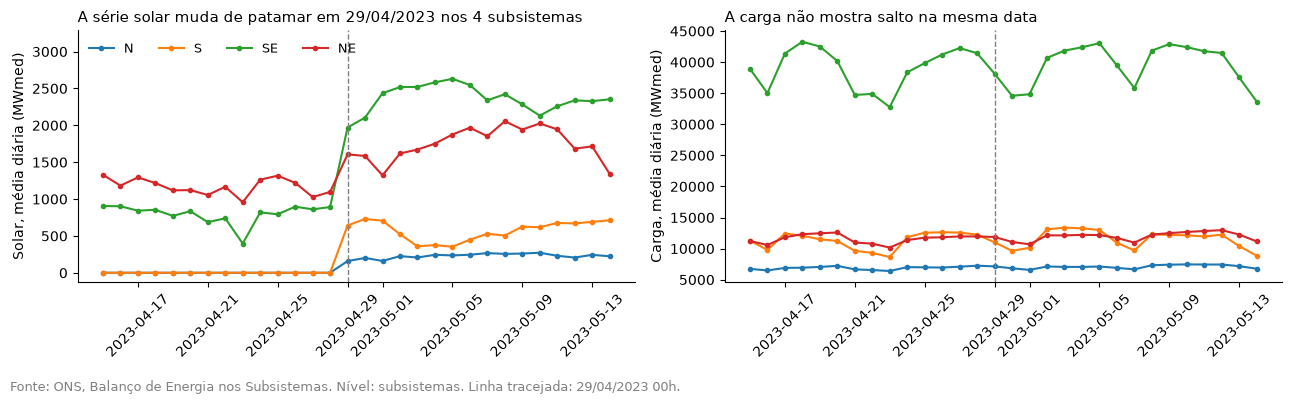

In [4]:
janela = subs_bruto[subs_bruto["din_instante"].between("2023-04-15", "2023-05-14 23:00")]
diario = (janela.assign(data=janela["din_instante"].dt.normalize())
          .groupby(["data", "id_subsistema"], observed=True)[["val_gersolar", "val_carga"]].mean()
          .unstack("id_subsistema"))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for sub in ["N", "S", "SE", "NE"]:
    eixos[0].plot(diario.index, diario[("val_gersolar", sub)], marker=".", label=sub)
    eixos[1].plot(diario.index, diario[("val_carga", sub)], marker=".", label=sub)
for eixo in eixos:
    eixo.axvline(ind.QUEBRA_SOLAR, color="gray", linestyle="--", linewidth=1)
    eixo.spines[["top", "right"]].set_visible(False)
    eixo.tick_params(axis="x", rotation=45)
eixos[0].set_title("A série solar muda de patamar em 29/04/2023 nos 4 subsistemas", loc="left", fontsize=11)
eixos[0].set_ylabel("Solar, média diária (MWmed)")
eixos[1].set_title("A carga não mostra salto na mesma data", loc="left", fontsize=11)
eixos[1].set_ylabel("Carga, média diária (MWmed)")
eixos[0].legend(frameon=False, ncols=4, loc="upper left", bbox_to_anchor=(0, 1.0), fontsize=9)
eixos[0].set_ylim(top=diario["val_gersolar"].max().max() * 1.25)
fig.text(0.01, 0.01, "Fonte: ONS, Balanço de Energia nos Subsistemas. Nível: subsistemas. Linha tracejada: 29/04/2023 00h.", fontsize=9, color="gray")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(PASTA_FIGURAS / "02_quebra_serie_solar_2023.png", dpi=150)
plt.show()

In [5]:
meio_dia = subs_bruto[(subs_bruto["din_instante"].dt.hour == 12)
                     & subs_bruto["din_instante"].between("2023-04-27", "2023-04-30 23:00")]
meio_dia.pivot_table(index="din_instante", columns="id_subsistema", values="val_gersolar", observed=True).round(0)

id_subsistema,N,NE,S,SE
din_instante,,,,
2023-04-27 12:00:00,4.0,2665.0,1.0,2328.0
2023-04-28 12:00:00,4.0,3135.0,1.0,2549.0
2023-04-29 12:00:00,656.0,4917.0,2508.0,6907.0
2023-04-30 12:00:00,678.0,5085.0,2543.0,7026.0


**Leitura:** a partir de 29/04/2023 00h, ao meio-dia, a solar passa de ~4 para ~650 MWmed no Norte, de ~1 para ~2.500 MWmed no Sul, de ~2.500 para ~6.900 MWmed no SE e de ~3.100 para ~4.900 MWmed no NE, enquanto a carga não mostra salto. É uma **mudança de cobertura ou classificação da série** (o motivo exato não está documentado na base e fica *a confirmar* no ONS), não uma expansão física de um dia para o outro.

**Decisão (DA-018):**
1. Coluna `cobertura_solar_parcial` para todos os subsistemas e o SIN antes de 29/04/2023. Nenhum valor é alterado ou removido.
2. Comparações anuais de indicadores com carga residual usam **maio a dezembro** (`mes_comparavel`), período comparável nos três anos.
3. O limiar de carga residual baixa usa **2024** como referência.
4. O índice de vale usa apenas a carga e não é afetado pela quebra.

## 5. Variáveis derivadas e flags de incidentes

In [6]:
base_subs = ind.preparar_base_horaria(subs_bruto)
base_sin = ind.preparar_base_horaria(sin_bruto)

# Os valores originais permanecem idênticos
for bruto, base in ((subs_bruto, base_subs), (sin_bruto, base_sin)):
    original = bruto.sort_values(["id_subsistema", "din_instante"])["val_gersolar"].to_numpy()
    assert np.array_equal(original, base["val_gersolar"].to_numpy())
print(base_subs.shape, base_sin.shape)

(105216, 31) (26304, 31)


Regras de sinalização da solar (limiares relativos ao máximo anual do próprio subsistema, porque a capacidade cresce entre os anos):

- `flag_solar_noturna_alta`: entre 21h e 4h com solar > 2% do máximo anual;
- `flag_solar_zero_diurna`: entre 10h e 15h com solar ≤ 1% do máximo anual (depois da quebra);
- `flag_solar_congelada`: o mesmo valor repetido por ≥ 4 horas seguidas, acima de 2% do máximo anual.

In [7]:
resumo_flags = pd.concat([ind.resumo_flags(base_subs), ind.resumo_flags(base_sin)])
resumo_flags

flag_solar_noturna_alta  flag_solar_zero_diurna  \
id_subsistema ano                                                     
N             2023                        0                       0   
              2024                        5                       6   
              2025                        0                       0   
NE            2023                        0                       0   
              2024                        5                       0   
              2025                       10                       0   
S             2023                        0                       0   
              2024                        8                       6   
              2025                        0                       0   
SE            2023                        0                       0   
              2024                        5                       0   
              2025                        0                       0   
SIN           2023                        0                       0   
              2024                        5                       0   
              2025                        0                       0   

                    flag_solar_congelada  flag_suspeito  
id_subsistema ano                                        
N             2023                     0              0  
              2024                     8             14  
              2025                     0              0  
NE            2023                     0              0  
              2024                     5              5  
              2025                     0             10  
S             2023                     0              0  
              2024                    13             19  
              2025                     0              0  
SE            2023                     0              0  
              2024                     5              5  
              2025                     0              0  
SIN           2023                     0              0  
              2024                     5              5  
              2025                     0              0

In [8]:
horas_sinalizadas = pd.concat([base_subs, base_sin]).query("flag_suspeito")
casos = (horas_sinalizadas.groupby(["id_subsistema", "data"])
         .agg(horas=("hora", "size"), primeira=("hora", "min"), ultima=("hora", "max"),
              solar_max=("val_gersolar", "max"))
         .round(0))
casos

horas  primeira  ultima  solar_max
id_subsistema data                                          
N             2024-11-09      6        10      15        0.0
              2024-11-10      8         0       7      674.0
NE            2024-11-10      5         0       4     2360.0
              2025-10-18      8         0      23      684.0
              2025-10-20      2        21      22      362.0
S             2024-11-09      6        10      15        1.0
              2024-11-10     13         0      23     2256.0
SE            2024-11-10      5         0       4     2876.0
SIN           2024-11-10      5         0       4     8166.0

**Leitura:** os incidentes se concentram em **09–10/11/2024** em todos os subsistemas. No dia 9, a solar do Norte fica zerada e a do Sul travada em ~1 MWmed durante o dia. Na madrugada do dia 10, os valores ficam congelados e repetidos (por exemplo, 2.876 MWmed no SE entre 00h e 04h). No NE, há ainda **18 e 20/10/2025**, com solar noturna acima do limiar. São falhas de registro plausíveis, não geração real.

**Decisão (DA-019):** os dias com qualquer flag recebem `dia_suspeito = True`. Eles **não são removidos**. As análises principais os excluem, e a Fase 4 compara os resultados com e sem eles.

## 6. Apagão de 15/08/2023 (evento operativo)

Em 15/08/2023, às 8h30, uma perturbação no SIN interrompeu o fornecimento em 25 estados e no Distrito Federal. Diferentemente dos incidentes da seção 5, **é um evento real**, e aparece nos dados como queda brusca da carga e da geração eólica. A comparação usa as terças-feiras anterior e seguinte (08 e 22/08).

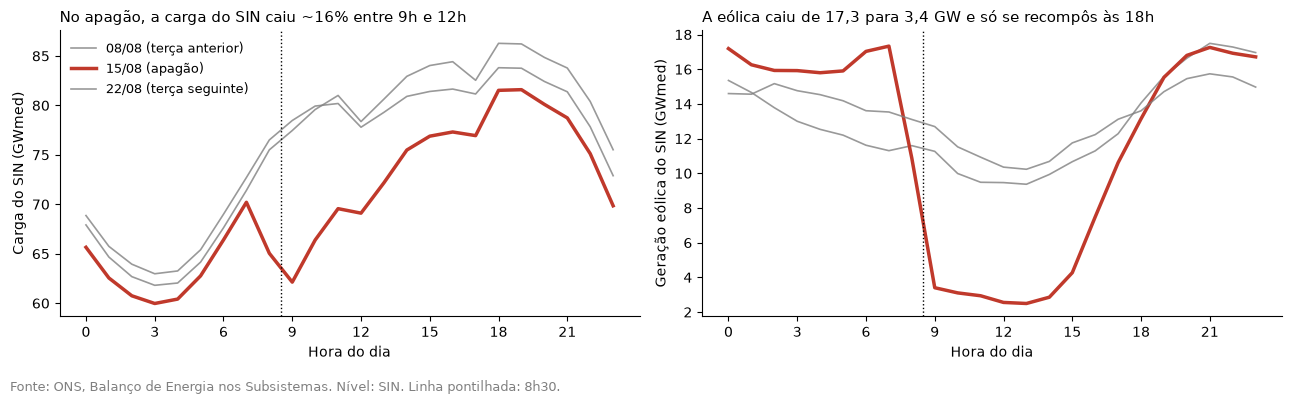

In [9]:
sin_h = sin_bruto.assign(data=sin_bruto["din_instante"].dt.normalize(), hora=sin_bruto["din_instante"].dt.hour)
datas = {"08/08 (terça anterior)": "2023-08-08", "15/08 (apagão)": "2023-08-15", "22/08 (terça seguinte)": "2023-08-22"}
fig, eixos = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for rotulo, data in datas.items():
    dia = sin_h[sin_h["data"] == data]
    estilo = dict(color="#c0392b", linewidth=2.5) if "apagão" in rotulo else dict(color="gray", linewidth=1.2, alpha=0.8)
    eixos[0].plot(dia["hora"], dia["val_carga"] / 1000, label=rotulo, **estilo)
    eixos[1].plot(dia["hora"], dia["val_gereolica"] / 1000, label=rotulo, **estilo)
eixos[0].set_title("No apagão, a carga do SIN caiu ~16% entre 9h e 12h", loc="left", fontsize=11)
eixos[0].set_ylabel("Carga do SIN (GWmed)")
eixos[1].set_title("A eólica caiu de 17,3 para 3,4 GW e só se recompôs às 18h", loc="left", fontsize=11)
eixos[1].set_ylabel("Geração eólica do SIN (GWmed)")
for eixo in eixos:
    eixo.axvline(8.5, color="black", linestyle=":", linewidth=1)
    eixo.set_xlabel("Hora do dia"); eixo.set_xticks(range(0, 24, 3))
    eixo.spines[["top", "right"]].set_visible(False)
eixos[0].legend(frameon=False, fontsize=9)
fig.text(0.01, 0.01, "Fonte: ONS, Balanço de Energia nos Subsistemas. Nível: SIN. Linha pontilhada: 8h30.", fontsize=9, color="gray")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(PASTA_FIGURAS / "02_apagao_15ago2023.png", dpi=150)
plt.show()

In [10]:
janela_manha = sin_h[sin_h["hora"].between(9, 12)].groupby("data")["val_carga"].mean()
comparacao = janela_manha.loc[list(datas.values())].rename(index=dict(zip(pd.to_datetime(list(datas.values())), datas.keys())))
print((comparacao / 1000).round(1).to_string())
print(f"Queda frente à média das terças vizinhas: {comparacao.iloc[1] / comparacao.iloc[[0, 2]].mean() - 1:.1%}")
sub_h = subs_bruto[subs_bruto["din_instante"].between("2023-08-15 06:00", "2023-08-15 15:00")]
sub_h.pivot_table(index="din_instante", columns="id_subsistema", values="val_carga", observed=True).round(0)

data
08/08 (terça anterior)    79.1
15/08 (apagão)            66.8
22/08 (terça seguinte)    79.1
Queda frente à média das terças vizinhas: -15.6%


id_subsistema,N,NE,S,SE
din_instante,,,,
2023-08-15 06:00:00,6835.0,10786.0,11083.0,37695.0
2023-08-15 07:00:00,6822.0,11447.0,12333.0,39602.0
2023-08-15 08:00:00,4538.0,9560.0,12461.0,38483.0
2023-08-15 09:00:00,1364.0,7358.0,12849.0,40557.0
2023-08-15 10:00:00,2063.0,8396.0,13313.0,42616.0
2023-08-15 11:00:00,2770.0,9697.0,13317.0,43774.0
2023-08-15 12:00:00,4251.0,9644.0,12126.0,43083.0
2023-08-15 13:00:00,5440.0,10534.0,12436.0,43764.0
2023-08-15 14:00:00,6676.0,11449.0,12703.0,44660.0


**Leitura:** a queda da carga é mais intensa no Norte (de ~6.800 MWmed às 7h para ~1.400 MWmed às 9h) e no Nordeste, com recuperação por volta das 14h–15h. A eólica do SIN fica abaixo de 5 GW até as 15h e só volta ao patamar habitual por volta das 18h. Como o evento cai **dentro** da janela do vale (10h–15h), ele distorceria o índice de vale, a carga residual mínima e a rampa desse dia.

**Decisão (DA-020):** marcar 15/08/2023 como `evento_operativo` em todos os níveis. Ele entra em `dia_atipico`, fica fora da análise principal e entra na sensibilidade. Nenhum valor é alterado.

## 7. Feriados nacionais e consolidação dos dias atípicos

Na varredura dos dias de menor carga, quase todos são **feriados** (1º de janeiro, Natal, Sexta-feira Santa, Tiradentes, Carnaval...). Feriados são efeito de calendário, não anomalia: entram como **controle** (`feriado`, `dia_util`), não como exclusão (DA-021).

O incidente de 09–10/11/2024 também afetou a **carga**: sem a solar de N e S durante o dia 9, a carga calculada pelo balanço ficou ~20% abaixo dos sábados vizinhos no Sul. Por isso, as datas com incidente passam a valer para **todos os níveis**, incluindo o SIN.

In [11]:
feriados = ind.feriados_nacionais([2023, 2024, 2025])
print(len(feriados), "feriados e pontos facultativos nacionais no período")
feriados.head(12)

38 feriados e pontos facultativos nacionais no período


,data,feriado_nome
0,2023-01-01,Confraternização Universal
1,2023-02-20,Carnaval (segunda)
2,2023-02-21,Carnaval (terça)
3,2023-04-07,Sexta-feira Santa
4,2023-04-21,Tiradentes
5,2023-05-01,Dia do Trabalho
6,2023-06-08,Corpus Christi
7,2023-09-07,Independência
8,2023-10-12,Nossa Senhora Aparecida
9,2023-11-02,Finados


## 8. Indicadores diários

In [12]:
diarios_subs = ind.indicadores_diarios(base_subs)
diarios_sin = ind.indicadores_diarios(base_sin)
assert len(diarios_subs) == 1096 * 4 and len(diarios_sin) == 1096
assert diarios_subs.notna().all().all() and diarios_sin.notna().all().all()
diarios = ind.consolidar_dias_atipicos(pd.concat([diarios_sin, diarios_subs], ignore_index=True))
(diarios.groupby("id_subsistema")[["dia_suspeito", "evento_operativo", "dia_atipico", "feriado", "cobertura_solar_parcial"]]
 .sum())

,dia_suspeito,evento_operativo,dia_atipico,feriado,cobertura_solar_parcial
id_subsistema,,,,,
N,4,1,5,38,118
NE,4,1,5,38,118
S,4,1,5,38,118
SE,4,1,5,38,118
SIN,4,1,5,38,118


| Indicador | Fórmula | Unidade | Hipótese |
|---|---|---|---|
| `indice_vale` | média da carga 10–15h ÷ média da carga do dia | adimensional | H1 (menor = vale mais profundo) |
| `carga_residual_min` | mínimo da carga residual 10–15h | MWmed | H2, H3 |
| `rampa_tarde` | média da carga residual 18–20h − `carga_residual_min` | MWmed | H2 |
| `maior_rampa_horaria` | maior subida horária da carga residual 16–21h | MWmed/h | H2 |
| `horas_residual_baixa` | horas do dia abaixo do P10 de 2024 (subsistema × mês) | horas | H3 |
| `intercambio_medio_vale` | média do intercâmbio 10–15h (positivo = exportação) | MWmed | H5 |
| `participacao_eol_sol` | (eólica + solar) ÷ geração centralizada, no dia | proporção | contexto |
| `dia_atipico` | `dia_suspeito` ou `evento_operativo` | booleano | excluído da análise principal |
| `feriado`, `dia_util` | calendário nacional | booleano | controle |

## 9. Primeira leitura: médias anuais em meses comparáveis (maio a dezembro, sem dias atípicos)

Tabela descritiva, sem teste estatístico. A interpretação e os testes ficam para as Fases 3 e 4.

In [13]:
colunas = ["indice_vale", "carga_residual_min", "rampa_tarde", "maior_rampa_horaria", "horas_residual_baixa"]
comparavel = diarios[diarios["mes_comparavel"] & ~diarios["dia_atipico"]]
media_anual = comparavel.groupby(["id_subsistema", "ano"])[colunas].mean()
media_anual.round(3)

indice_vale  carga_residual_min  rampa_tarde  \
id_subsistema ano                                                  
N             2023        1.012            6039.077     1248.841   
              2024        1.014            6177.872     1770.616   
              2025        1.014            6200.807     2228.121   
NE            2023        1.012           -3148.622     4374.127   
              2024        0.992           -5511.340     5020.518   
              2025        0.956           -5003.262     3264.399   
S             2023        1.078            9543.334     4113.913   
              2024        1.074            9487.189     4904.620   
              2025        1.039            8501.891     6436.944   
SE            2023        1.057           34584.672    12819.354   
              2024        1.054           32700.254    16473.760   
              2025        1.033           27758.951    21385.443   
SIN           2023        1.049           48074.012    21500.686   
              2024        1.043           43897.122    27126.369   
              2025        1.019           39524.618    31248.676   

                    maior_rampa_horaria  horas_residual_baixa  
id_subsistema ano                                              
N             2023              257.515                 4.857  
              2024              276.026                 2.387  
              2025              319.824                 2.198  
NE            2023             1413.342                 0.574  
              2024             1821.632                 2.428  
              2025             1773.607                 3.708  
S             2023             1093.136                 3.107  
              2024             1200.395                 2.342  
              2025             1579.813                 2.848  
SE            2023             3158.406                 2.627  
              2024             3991.345                 2.383  
              2025             6066.519                 6.029  
SIN           2023             4856.182                 1.799  
              2024             6575.583                 2.379  
              2025             9319.668                 4.901

## 10. Exportação

In [ ]:
base_horaria = pd.concat([base_sin, base_subs], ignore_index=True)
base_horaria.to_parquet(PASTA_PROCESSADOS / "base_horaria.parquet", index=False)
diarios.to_parquet(PASTA_PROCESSADOS / "indicadores_diarios.parquet", index=False)
resumo_flags.to_csv(PASTA_TABELAS / "02_resumo_flags_solar.csv")
feriados.to_csv(PASTA_TABELAS / "02_feriados_nacionais.csv", index=False)
casos.to_csv(PASTA_TABELAS / "02_casos_sinalizados.csv")
media_anual.round(3).to_csv(PASTA_TABELAS / "02_media_anual_indicadores_mai_dez.csv")
for arquivo in sorted(PASTA_PROCESSADOS.glob("*.parquet")):
    print(arquivo.name, f"{arquivo.stat().st_size / 1e6:.1f} MB")

base_horaria.parquet 11.1 MB
indicadores_diarios.parquet 0.5 MB


: 

## 11. Registro dos tratamentos (tabela 4.2 do roteiro)

| Tratamento | Justificativa | Impacto ou validação |
|---|---|---|
| Variáveis temporais e `periodo_dia` | Comparar horas, dias e meses | Testes em `tests/test_indicadores.py` |
| `carga_residual = carga − eólica − solar` | Medir o que sobra para as fontes controláveis | Identidade testada |
| `cobertura_solar_parcial` (todos os níveis, antes de 29/04/2023) | Quebra de cobertura da série solar | 118 dias por subsistema; comparações anuais em maio a dezembro |
| Flags de incidente da solar → `dia_suspeito` | Falhas de registro (09–10/11/2024; NE 18 e 20/10/2025), que também afetam a carga | Propagadas para todos os níveis na data: 4 datas × 5 níveis; valores preservados |
| `evento_operativo` em 15/08/2023 | Apagão real no SIN às 8h30 | 1 data × 5 níveis; com `dia_suspeito` forma `dia_atipico`, excluído da análise principal, com sensibilidade |
| `feriado` e `dia_util` | Efeito de calendário | Controle no modelo; não exclui dias |
| Limiar P10 de 2024 por subsistema × mês | Linha de base fixa e comparável | ~10% das horas de 2024 abaixo do limiar (testado) |
| Indicadores diários | Responder H1–H5 | 4.384 linhas (subsistemas) + 1.096 (SIN), sem ausentes |